# Minimum-Variance Weights under Target Factor Exposures

A portfolio can minimize variance while meeting exact target exposures as follows:

$$
\min_{w\in\mathbb R^N} w^{\mathsf T}Vw
\qquad\text{subject to}\qquad
B^{\mathsf T}w=c.
$$

Here, $N$ is the number of assets, $w$ is the asset-weight vector, $V$ is the positive-definite asset covariance matrix, $B$ is the $N\times K$ matrix of supplied asset exposures to $K$ factors, $c$ is the vector of requested factor exposures, and $\mathsf T$ denotes transpose.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
from dataclasses import FrozenInstanceError, fields
import inspect
import math
import re
import sys
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import ndtr
from scipy.stats import norm
from IPython.display import Image
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import io
import zipfile
DATA_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'ken_french'
DATA_PATH = ensure_dataset(ROOT, 'french_49_industries')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode('latin1').splitlines()
header_row = next((index for index, line in enumerate(public_lines) if line.startswith(',Agric')))
end_row = next((index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip()))
raw = pd.read_csv(io.StringIO('\n'.join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: 'Date'})
raw['Date'] = pd.to_datetime(raw['Date'].astype(str), format='%Y%m%d')
raw = raw.set_index('Date').replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc['2019-01-01':'2025-12-31'].dropna().copy()
from RiskLabAI.causal_factor_analysis import AllocationMisspecificationDiagnostics, FDRComparisonEvidence, FDRNonIdentificationWitness, GaussianSearchAdjustedFDR, GaussianTrialMixture, MaxSelectionFamilyErrors, SelectionLevelProbabilityEvidence, allocation_misspecification_diagnostics, compare_single_and_family_fdr, conditional_upper_tail_probability, family_level_false_discovery_rate, fdr_nonidentification_witness, gaussian_max_selection_cdf, gaussian_max_selection_log_density, gaussian_max_selection_log_likelihood, gaussian_search_adjusted_false_discovery_rate, gaussian_trial_mixture_cdf, max_selection_family_errors, max_selection_null_probability, maximum_mixture_cdf, minimum_variance_factor_weights, single_trial_false_discovery_rate
FIGURES = ROOT / 'outputs' / 'figures' / '08_search_adjusted_portfolios'
TABLES = ROOT / 'outputs' / 'tables' / '08_search_adjusted_portfolios'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return '0'
    return f'{value:.6f}'.rstrip('0').rstrip('.')
pd.set_option('display.float_format', display_float)

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True, position='tbp'):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: 'Yes', False: 'No'})
    table_frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{adjustbox}{max width=\\textwidth}' + '\n' + '\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}' + '\n' + '\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = re.sub('(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])', 'Not available', latex)
    latex = re.sub('(?<![A-Za-z])inf(?![A-Za-z])', 'No finite value', latex)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', dpi=300)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    display(Image(filename=str(FIGURES / f'{stem}.png')))
    plt.close(figure)

def contract_result(name, action, expected):
    try:
        action()
        return {'Check': name, 'Expected result': expected, 'Observed result': 'Accepted', 'Passed': False}
    except Exception as error:
        return {'Check': name, 'Expected result': expected, 'Observed result': type(error).__name__, 'Passed': type(error).__name__ == expected}

def kkt_oracle(covariance, exposures, targets):
    asset_count, factor_count = exposures.shape
    system = np.block([[2.0 * covariance, exposures], [exposures.T, np.zeros((factor_count, factor_count))]])
    right_side = np.concatenate([np.zeros(asset_count), targets])
    solution = np.linalg.solve(system, right_side)
    return (solution[:asset_count], solution[asset_count:])

def portfolio_variance(covariance, weights):
    return float(weights @ covariance @ weights)

def normal_density(value, scale=1.0):
    return math.exp(-0.5 * (value / scale) ** 2) / (math.sqrt(2.0 * math.pi) * scale)
quick_covariance = np.diag([1.0, 2.0, 4.0])
quick_exposures = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
quick_targets = np.array([0.0, 1.0])
quick_weights = minimum_variance_factor_weights(quick_covariance, quick_exposures, quick_targets)
oracle_weights, quick_multipliers = kkt_oracle(quick_covariance, quick_exposures, quick_targets)
quick_achieved = quick_exposures.T @ quick_weights
quick_stationarity = 2.0 * quick_covariance @ quick_weights + quick_exposures @ quick_multipliers
quick_table = pd.DataFrame({'Asset': ['Asset 1', 'Asset 2', 'Asset 3'], 'Weight': quick_weights, 'Independent KKT weight': oracle_weights})
save_table(quick_table, 'allocation_quickstart_weights', 'Exact weights in the released three-asset example.', 'tab:chapter27-allocation-quickstart')
display(quick_table)
kkt_table = pd.DataFrame([{'Check': 'First target exposure', 'Value': quick_achieved[0], 'Required value': quick_targets[0], 'Absolute difference': abs(quick_achieved[0] - quick_targets[0])}, {'Check': 'Second target exposure', 'Value': quick_achieved[1], 'Required value': quick_targets[1], 'Absolute difference': abs(quick_achieved[1] - quick_targets[1])}, {'Check': 'Largest stationarity residual', 'Value': np.max(np.abs(quick_stationarity)), 'Required value': 0.0, 'Absolute difference': np.max(np.abs(quick_stationarity))}, {'Check': 'Portfolio variance', 'Value': portfolio_variance(quick_covariance, quick_weights), 'Required value': 10.0 / 7.0, 'Absolute difference': abs(portfolio_variance(quick_covariance, quick_weights) - 10.0 / 7.0)}])
save_table(kkt_table, 'allocation_kkt_checks', 'Exposure and first-order checks for the released allocation.', 'tab:chapter27-allocation-kkt')
display(kkt_table)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


,Asset,Weight,Independent KKT weight
0,Asset 1,-0.285714,-0.285714
1,Asset 2,0.714286,0.714286
2,Asset 3,0.285714,0.285714


,Check,Value,Required value,Absolute difference
0,First target exposure,0,0,0
1,Second target exposure,1,1,0
2,Largest stationarity residual,0,0,0
3,Portfolio variance,1.428571,1.428571,0


## Verifying the portfolio solution from first-order conditions

The unique solution and its first-order conditions are:

$$
w^{\star}=V^{-1}B(B^{\mathsf T}V^{-1}B)^{-1}c,
\qquad
2Vw^{\star}+B\lambda^{\star}=0,
\qquad
B^{\mathsf T}w^{\star}=c.
$$

Here, $w^{\star}$ is the minimum-variance weight vector, $V^{-1}$ denotes the inverse covariance operator, $B$ contains the supplied exposures, $c$ contains the targets, and $\lambda^{\star}$ is the vector of multipliers that balances the variance gradient against the exposure constraints.

,Perturbation,Portfolio variance,First exposure error,Second exposure error
0,-2,10.761905,0,0
1,-1,3.761905,0,0
2,0,1.428571,0,0
3,1,3.761905,0,0
4,2,10.761905,0,0


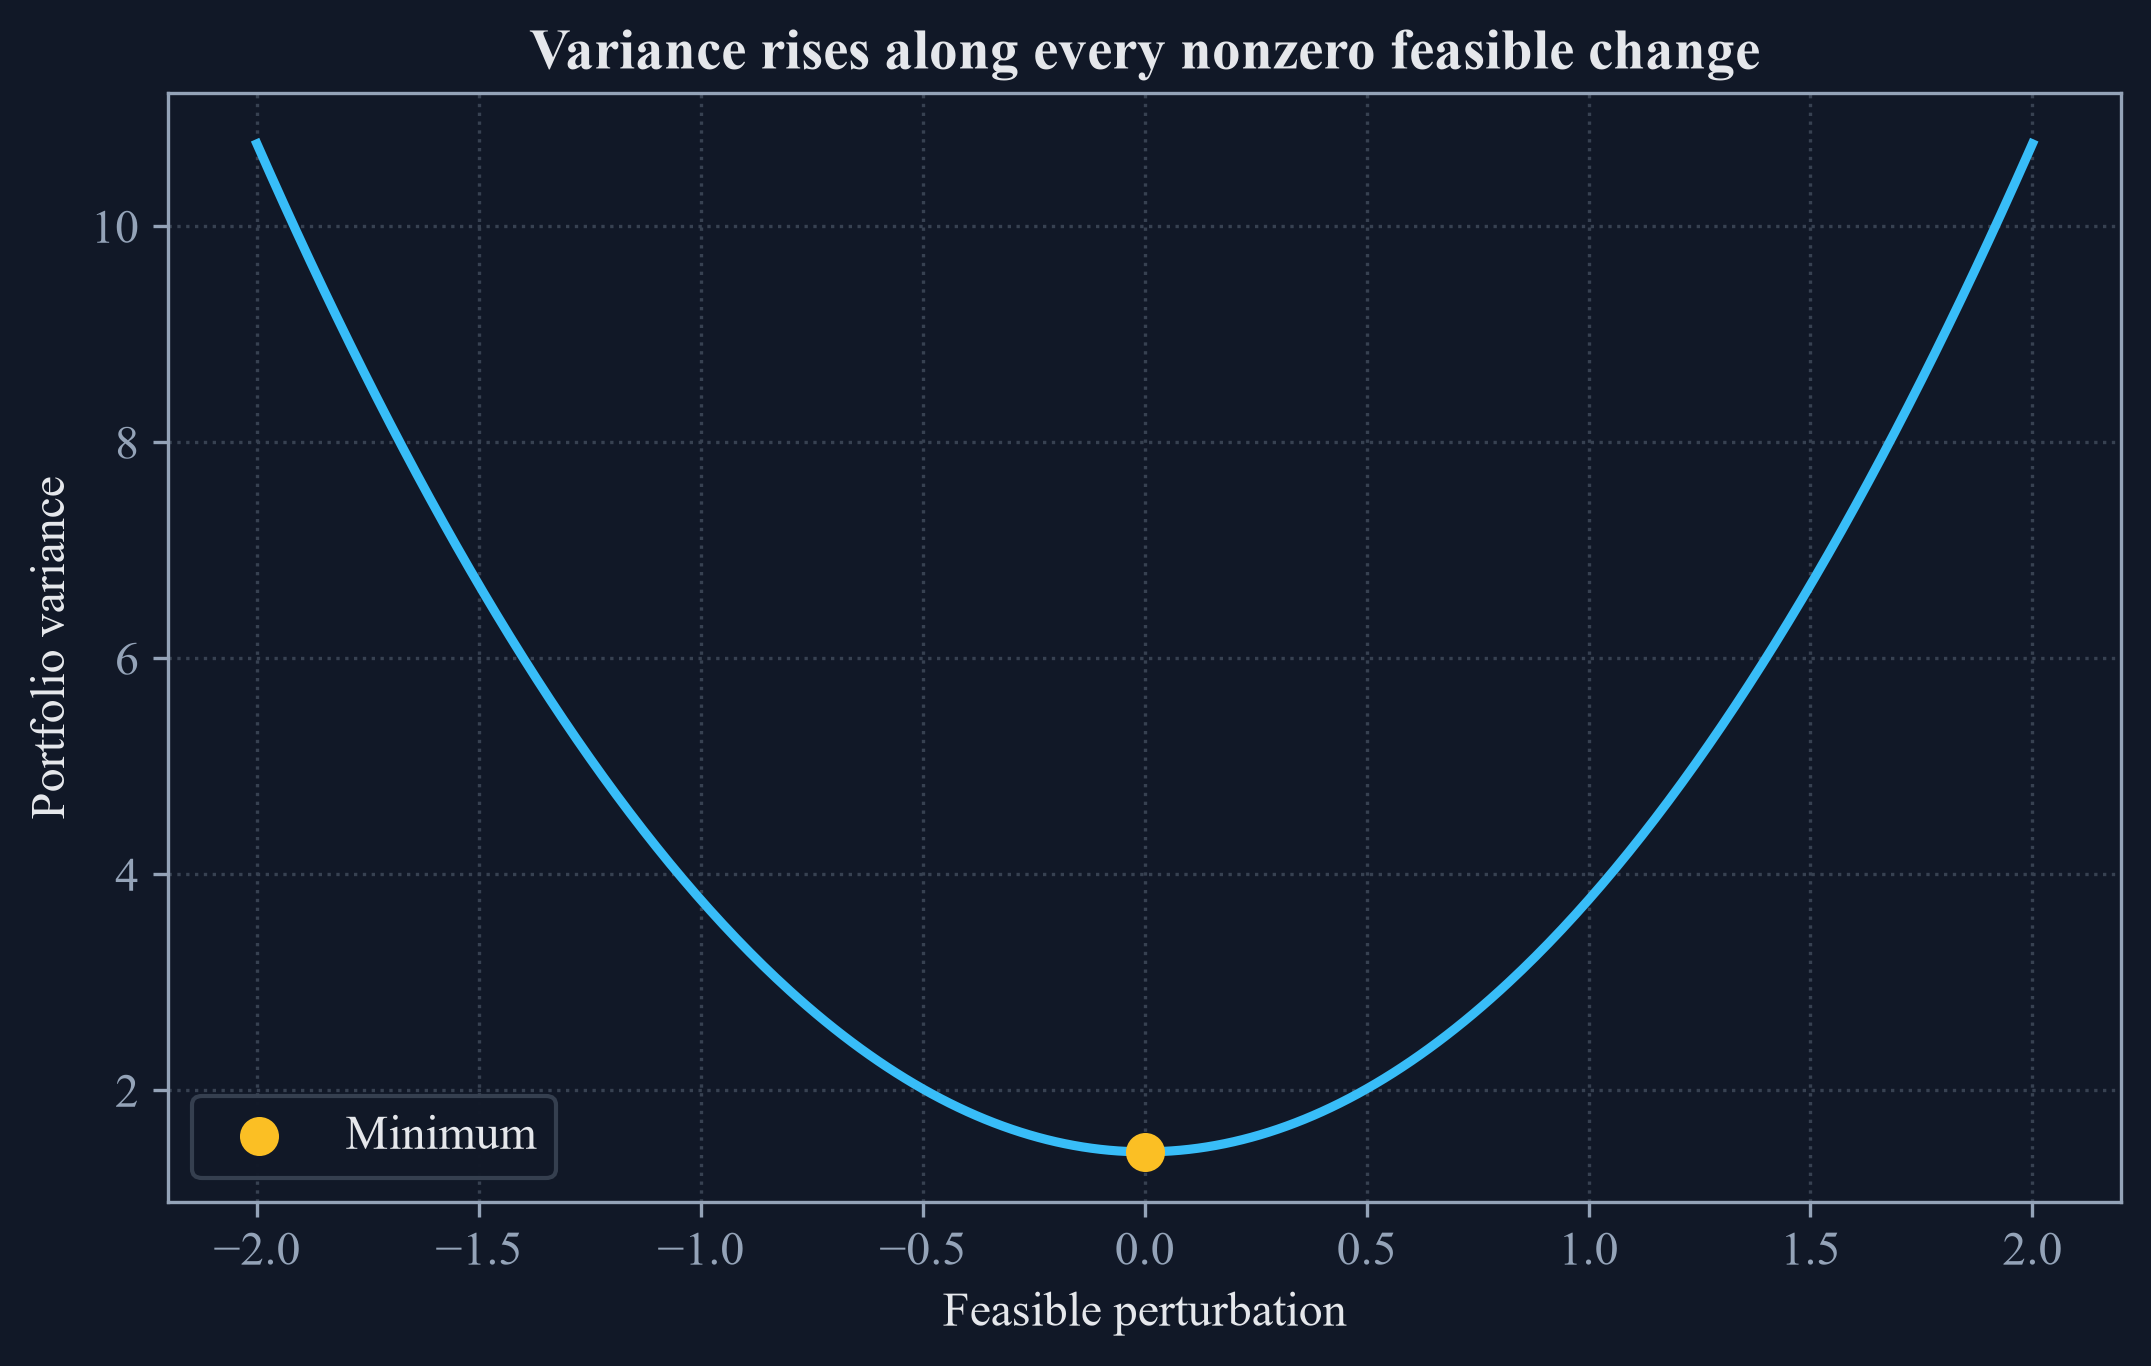

In [2]:
singular_vectors = np.linalg.svd(quick_exposures.T, full_matrices=True)[2]
feasible_direction = singular_vectors[-1]
feasible_direction = feasible_direction / np.linalg.norm(feasible_direction)
perturbations = np.linspace(-2.0, 2.0, 401)
feasible_weights = np.array([quick_weights + value * feasible_direction for value in perturbations])
feasible_variances = np.einsum("ij,jk,ik->i", feasible_weights, quick_covariance, feasible_weights)
selected_indices = [0, 100, 200, 300, 400]
feasible_table = pd.DataFrame({"Perturbation": perturbations[selected_indices], "Portfolio variance": feasible_variances[selected_indices], "First exposure error": [abs((quick_exposures.T @ feasible_weights[index] - quick_targets)[0]) for index in selected_indices], "Second exposure error": [abs((quick_exposures.T @ feasible_weights[index] - quick_targets)[1]) for index in selected_indices]})
save_table(feasible_table, "allocation_feasible_perturbations", "Variance along feasible changes around the optimum.", "tab:chapter27-allocation-feasible")
display(feasible_table)

figure, axis = plt.subplots(figsize=(8.4, 4.8))
axis.plot(perturbations, feasible_variances, color=palette["cyan"], linewidth=2.2)
axis.scatter([0.0], [portfolio_variance(quick_covariance, quick_weights)], color=palette["amber"], s=70, zorder=3, label="Minimum")
axis.set_xlabel("Feasible perturbation")
axis.set_ylabel("Portfolio variance")
axis.set_title("Variance rises along every nonzero feasible change")
axis.grid(True)
axis.legend()
save_figure(figure, "allocation_feasible_variance")

## Testing invariance under target rescaling

Scaling a target scales the weights, whereas scaling the whole covariance matrix leaves the weights unchanged:

$$
w^{\star}(V,B,ac)=a\,w^{\star}(V,B,c),
\qquad
w^{\star}(sV,B,c)=w^{\star}(V,B,c),
\quad s>0.
$$

Here, $a$ is any finite target scale, $s$ is a positive covariance-unit scale, and $w^{\star}(V,B,c)$ denotes the optimizer evaluated at covariance $V$, exposure matrix $B$, and target vector $c$.

,Second target,Asset 1 weight,Asset 2 weight,Asset 3 weight,Portfolio variance
0,-1.5,0.428571,-1.071429,-0.428571,3.214286
1,-1,0.285714,-0.714286,-0.285714,1.428571
2,0,0,0,0,0
3,1,-0.285714,0.714286,0.285714,1.428571
4,1.5,-0.428571,1.071429,0.428571,3.214286


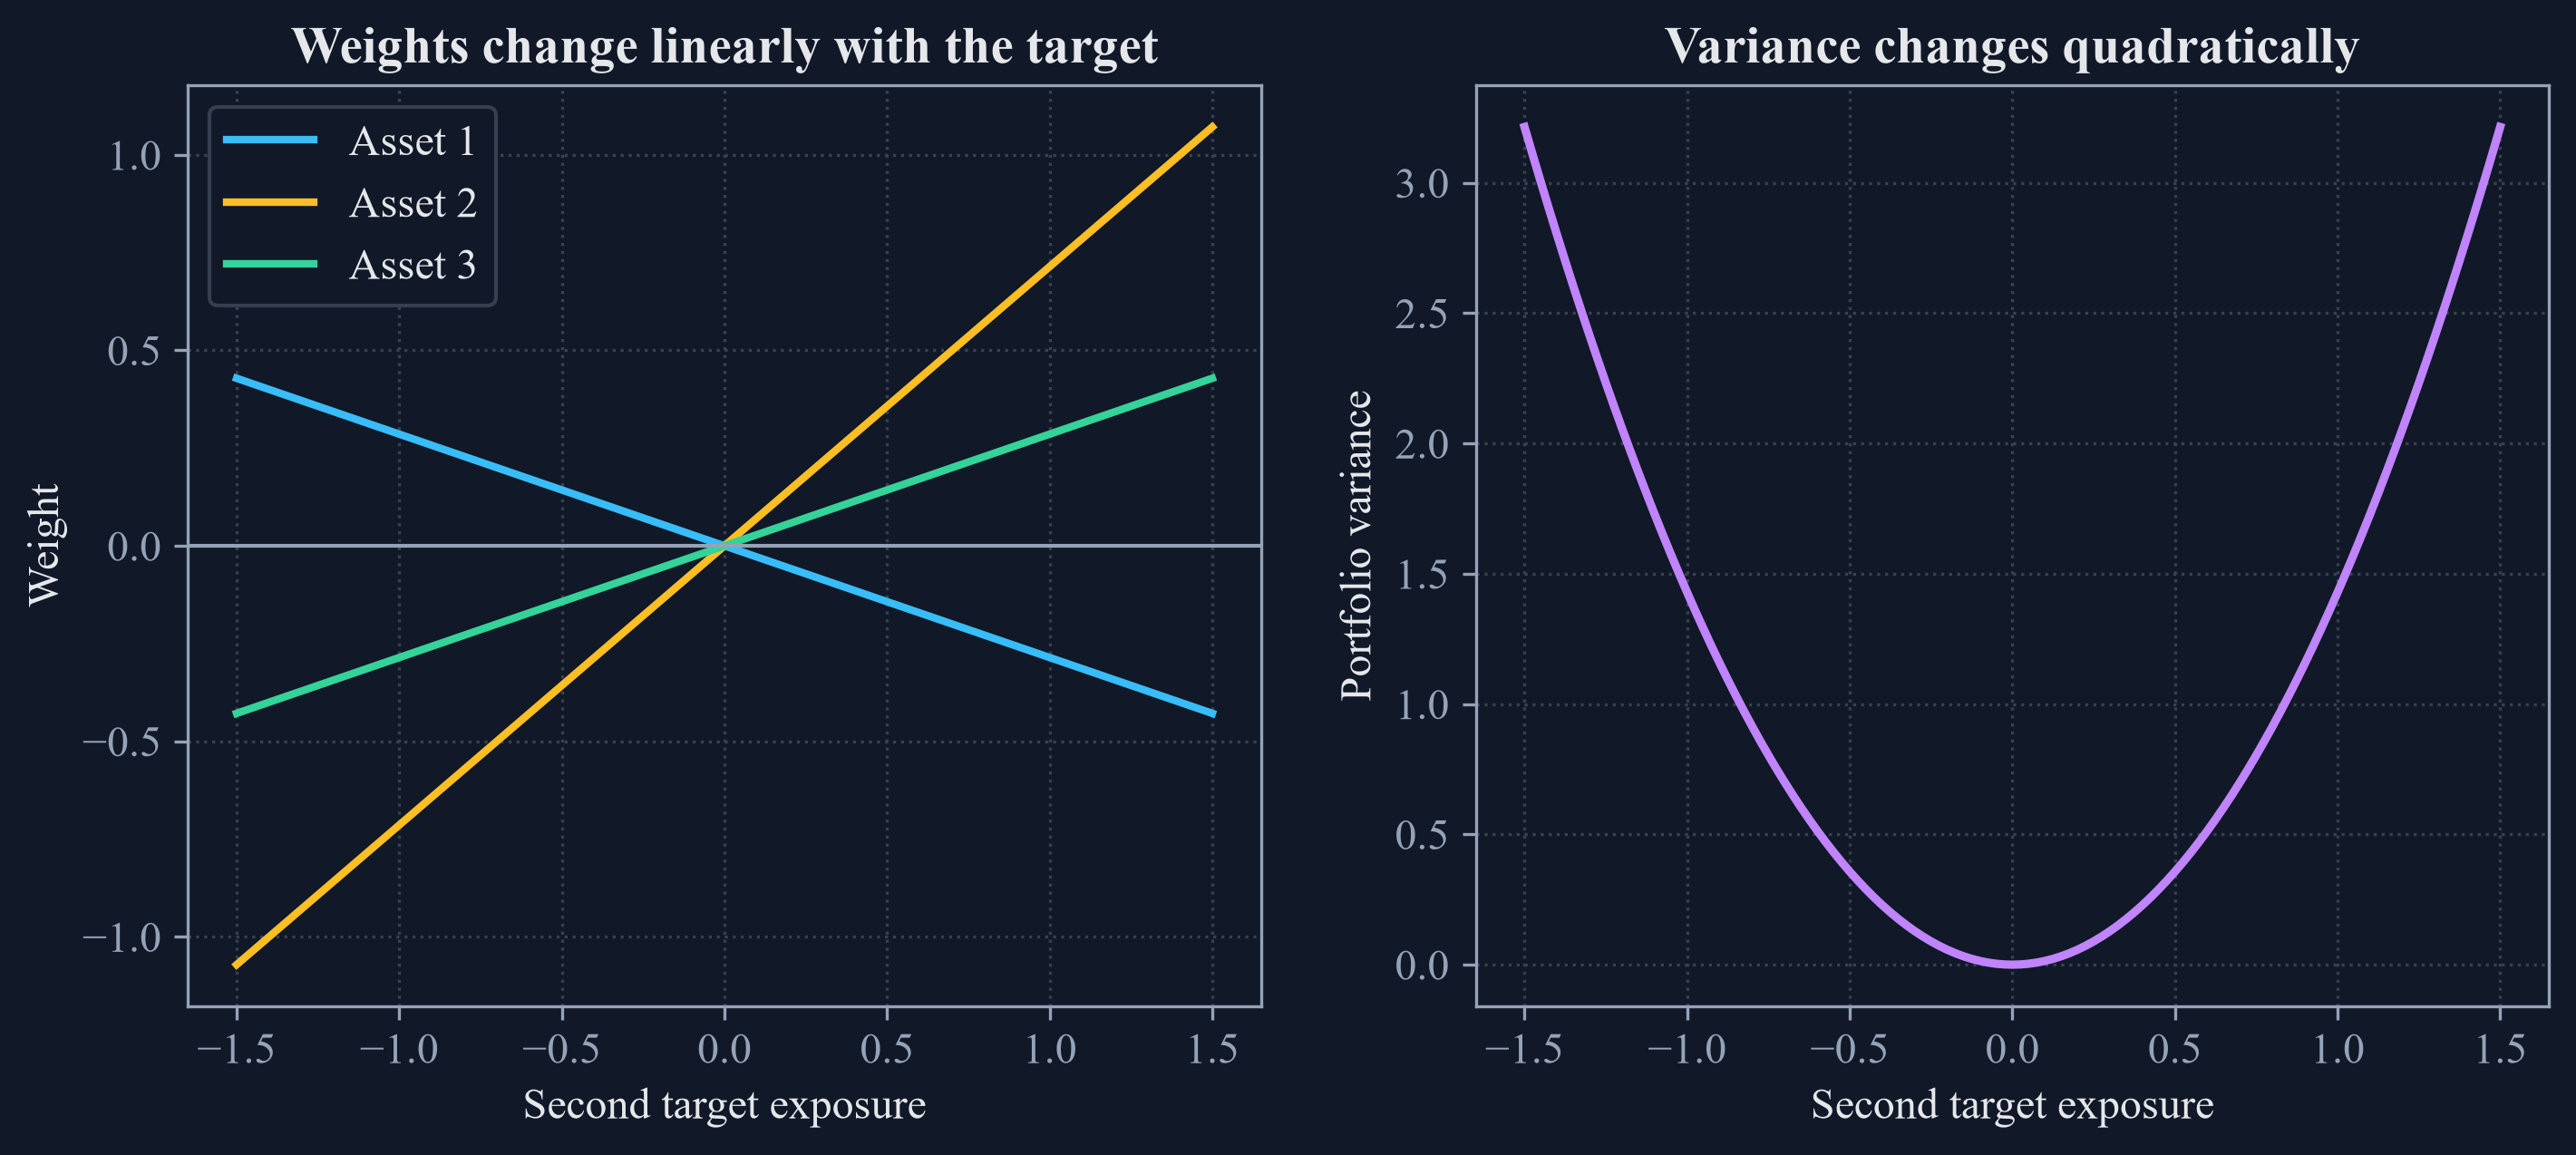

,Check,Scale,Largest weight difference,Passed
0,Covariance unit change,0,0,True
1,Covariance unit change,1,0,True
2,Covariance unit change,1000000000000,0,True
3,Target homogeneity,-3,0,True
4,Target homogeneity,0.25,0,True
5,Target homogeneity,4,0,True
6,Factor unit change,1,0,True
7,Asset and factor order,1,0,True


In [3]:
second_targets = np.linspace(-1.5, 1.5, 121)
target_weights = np.array([minimum_variance_factor_weights(quick_covariance, quick_exposures, [0.0, value]) for value in second_targets])
target_variances = np.array([portfolio_variance(quick_covariance, weights) for weights in target_weights])
target_rows = []
for value in [-1.5, -1.0, 0.0, 1.0, 1.5]:
    weights = minimum_variance_factor_weights(quick_covariance, quick_exposures, [0.0, value])
    target_rows.append({"Second target": value, "Asset 1 weight": weights[0], "Asset 2 weight": weights[1], "Asset 3 weight": weights[2], "Portfolio variance": portfolio_variance(quick_covariance, weights)})
target_table = pd.DataFrame(target_rows)
save_table(target_table, "allocation_target_sweep", "Weights and variance as the second target exposure changes.", "tab:chapter27-allocation-target-sweep")
display(target_table)

figure, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))
for index, color in enumerate([palette["cyan"], palette["amber"], palette["green"]]):
    axes[0].plot(second_targets, target_weights[:, index], color=color, linewidth=2.0, label=f"Asset {index + 1}")
axes[0].axhline(0.0, color=palette["muted"], linewidth=1.0)
axes[0].set_xlabel("Second target exposure")
axes[0].set_ylabel("Weight")
axes[0].set_title("Weights change linearly with the target")
axes[0].grid(True)
axes[0].legend()
axes[1].plot(second_targets, target_variances, color=palette["violet"], linewidth=2.2)
axes[1].set_xlabel("Second target exposure")
axes[1].set_ylabel("Portfolio variance")
axes[1].set_title("Variance changes quadratically")
axes[1].grid(True)
save_figure(figure, "allocation_target_paths")

invariance_rows = []
for scale in [1e-12, 1.0, 1e12]:
    observed = minimum_variance_factor_weights(scale * quick_covariance, quick_exposures, quick_targets)
    invariance_rows.append({"Check": "Covariance unit change", "Scale": scale, "Largest weight difference": np.max(np.abs(observed - quick_weights)), "Passed": np.allclose(observed, quick_weights, rtol=1e-12, atol=1e-12)})
for scale in [-3.0, 0.25, 4.0]:
    observed = minimum_variance_factor_weights(quick_covariance, quick_exposures, scale * quick_targets)
    invariance_rows.append({"Check": "Target homogeneity", "Scale": scale, "Largest weight difference": np.max(np.abs(observed - scale * quick_weights)), "Passed": np.allclose(observed, scale * quick_weights, rtol=1e-12, atol=1e-12)})
unit_scales = np.array([1e6, 1e-4])
unit_weights = minimum_variance_factor_weights(quick_covariance, quick_exposures * unit_scales, quick_targets * unit_scales)
invariance_rows.append({"Check": "Factor unit change", "Scale": 1.0, "Largest weight difference": np.max(np.abs(unit_weights - quick_weights)), "Passed": np.allclose(unit_weights, quick_weights, rtol=1e-12, atol=1e-12)})
asset_order = np.array([2, 0, 1])
factor_order = np.array([1, 0])
permuted = minimum_variance_factor_weights(quick_covariance[np.ix_(asset_order, asset_order)], quick_exposures[asset_order][:, factor_order], quick_targets[factor_order])
restored = np.empty_like(permuted)
restored[asset_order] = permuted
invariance_rows.append({"Check": "Asset and factor order", "Scale": 1.0, "Largest weight difference": np.max(np.abs(restored - quick_weights)), "Passed": np.allclose(restored, quick_weights, rtol=1e-12, atol=1e-12)})
invariance_table = pd.DataFrame(invariance_rows)
save_table(invariance_table, "allocation_invariance_checks", "Changes of units and order that preserve the allocation identities.", "tab:chapter27-allocation-invariance")
display(invariance_table)

## Square Exposure Systems

When the number of independent factor constraints equals the number of assets, the constraints determine the weights directly:

$$
K=N,
\qquad
w^{\star}=B^{-\mathsf T}c.
$$

Here, $K$ is the number of factor columns, $N$ is the number of assets, $B^{-\mathsf T}$ is the inverse transpose of the square exposure matrix, and $c$ is the target vector; covariance information no longer changes the solution because no free portfolio direction remains.

In [4]:
square_exposures = np.array([[1.0, 0.4], [-0.2, 1.0]])
square_targets = np.array([0.0, 1.0])
square_covariances = [np.array([[1.0, 0.2], [0.2, 2.0]]), np.array([[8.0, -1.0], [-1.0, 0.5]])]
direct_square = np.linalg.solve(square_exposures.T, square_targets)
square_rows = []
for index, covariance in enumerate(square_covariances, start=1):
    weights = minimum_variance_factor_weights(covariance, square_exposures, square_targets)
    square_rows.append({"Covariance case": index, "Asset 1 weight": weights[0], "Asset 2 weight": weights[1], "Largest difference from direct constraints": np.max(np.abs(weights - direct_square)), "Portfolio variance": portfolio_variance(covariance, weights)})
square_table = pd.DataFrame(square_rows)
save_table(square_table, "allocation_square_system", "Square exposure systems have covariance-independent weights.", "tab:chapter27-allocation-square")
display(square_table)

,Covariance case,Asset 1 weight,Asset 2 weight,Largest difference from direct constraints,Portfolio variance
0,1,0.185185,0.925926,0,1.817558
1,2,0.185185,0.925926,0,0.360082


## Public Industry Covariance Example

The public return history supplies an observed covariance estimate and the resulting portfolio variance:

$$
\widehat V=252\frac{1}{T-1}\sum_{t=1}^{T}(r_t-\bar r)(r_t-\bar r)^{\mathsf T},
\qquad
\widehat\sigma_p^2=w^{\mathsf T}\widehat Vw.
$$

Here, $T$ is the number of complete daily observations, $r_t$ is the vector of industry returns on date $t$, $\bar r$ is their sample mean, $\widehat V$ is the annualized sample covariance matrix, $w$ is a portfolio weight vector, and $\widehat\sigma_p^2$ is its estimated annual variance.

,Field,Value
0,Archive,49 Industry Portfolios daily archive
1,Provider,Kenneth R. French Data Library
2,Return type,Daily value-weighted return
3,Analysis start,2019-01-02
4,Analysis end,2025-12-31
5,Complete dates,1760
6,Industry portfolios,12


,Industry,Budget-only weight,Three-constraint weight,Supplied exposure one,Supplied exposure two
0,Agric,0.001686,-0.042347,-1,1
1,Food,0.568855,0.422701,-0.818182,0.959493
2,Soda,0.149008,0.077413,-0.636364,0.841254
3,Beer,-0.13242,-0.104523,-0.454545,0.654861
4,Smoke,0.079908,0.093962,-0.272727,0.415415
5,Toys,-0.018136,-0.043741,-0.090909,0.142315
6,Fun,0.091285,0.073096,0.090909,-0.142315
7,Books,0.075527,0.083342,0.272727,-0.415415
8,Hshld,0.192724,0.295234,0.454545,-0.654861
9,Clths,-0.078291,-0.069189,0.636364,-0.841254


,Constraint,Target,Achieved exposure,Absolute difference
0,Budget,1,1,0
1,Supplied exposure one,0,0,0
2,Supplied exposure two,0,0,0


,Portfolio,Annual variance,Annual volatility,Gross exposure,Largest absolute weight
0,Budget only,0.024218,0.155621,1.457694,0.568855
1,Three supplied targets,0.024974,0.158031,1.5196,0.422701


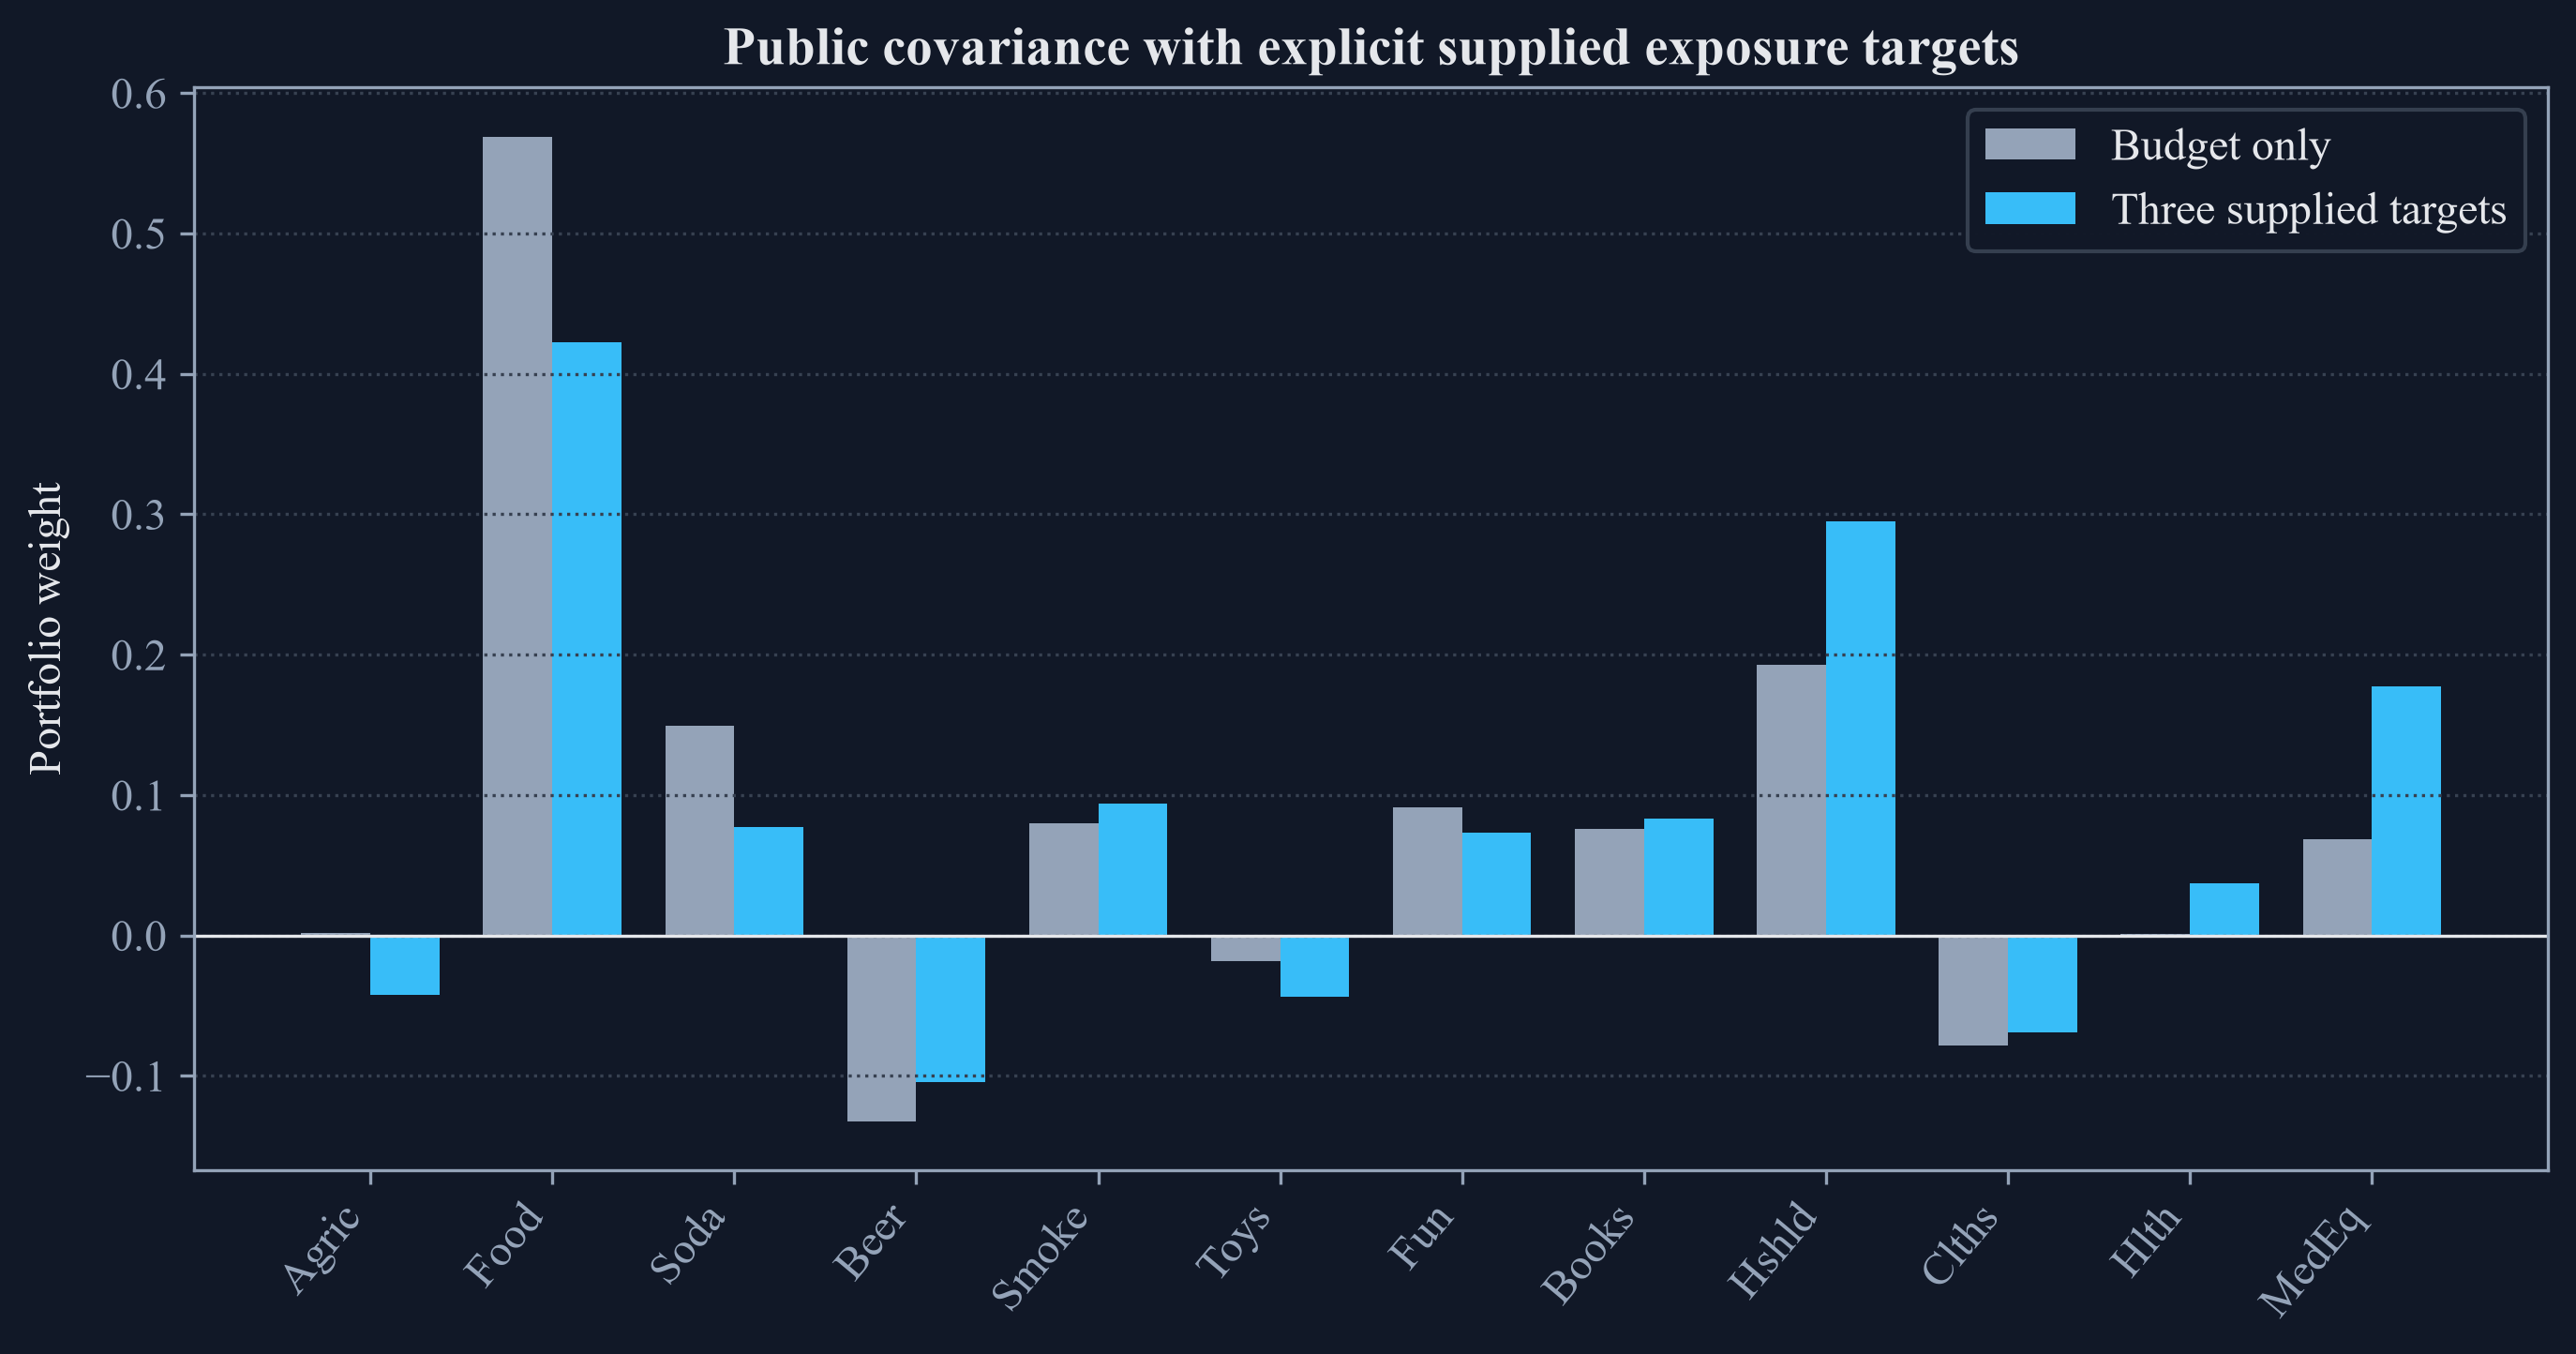

,Supplied exposure-one target,Annual variance,Annual volatility,Gross exposure
0,-0.6,0.086674,0.294405,6.764932
1,-0.3,0.038966,0.197399,3.754374
2,0,0.024974,0.158031,1.5196
3,0.3,0.044697,0.211417,2.843447
4,0.6,0.098137,0.313268,5.597503


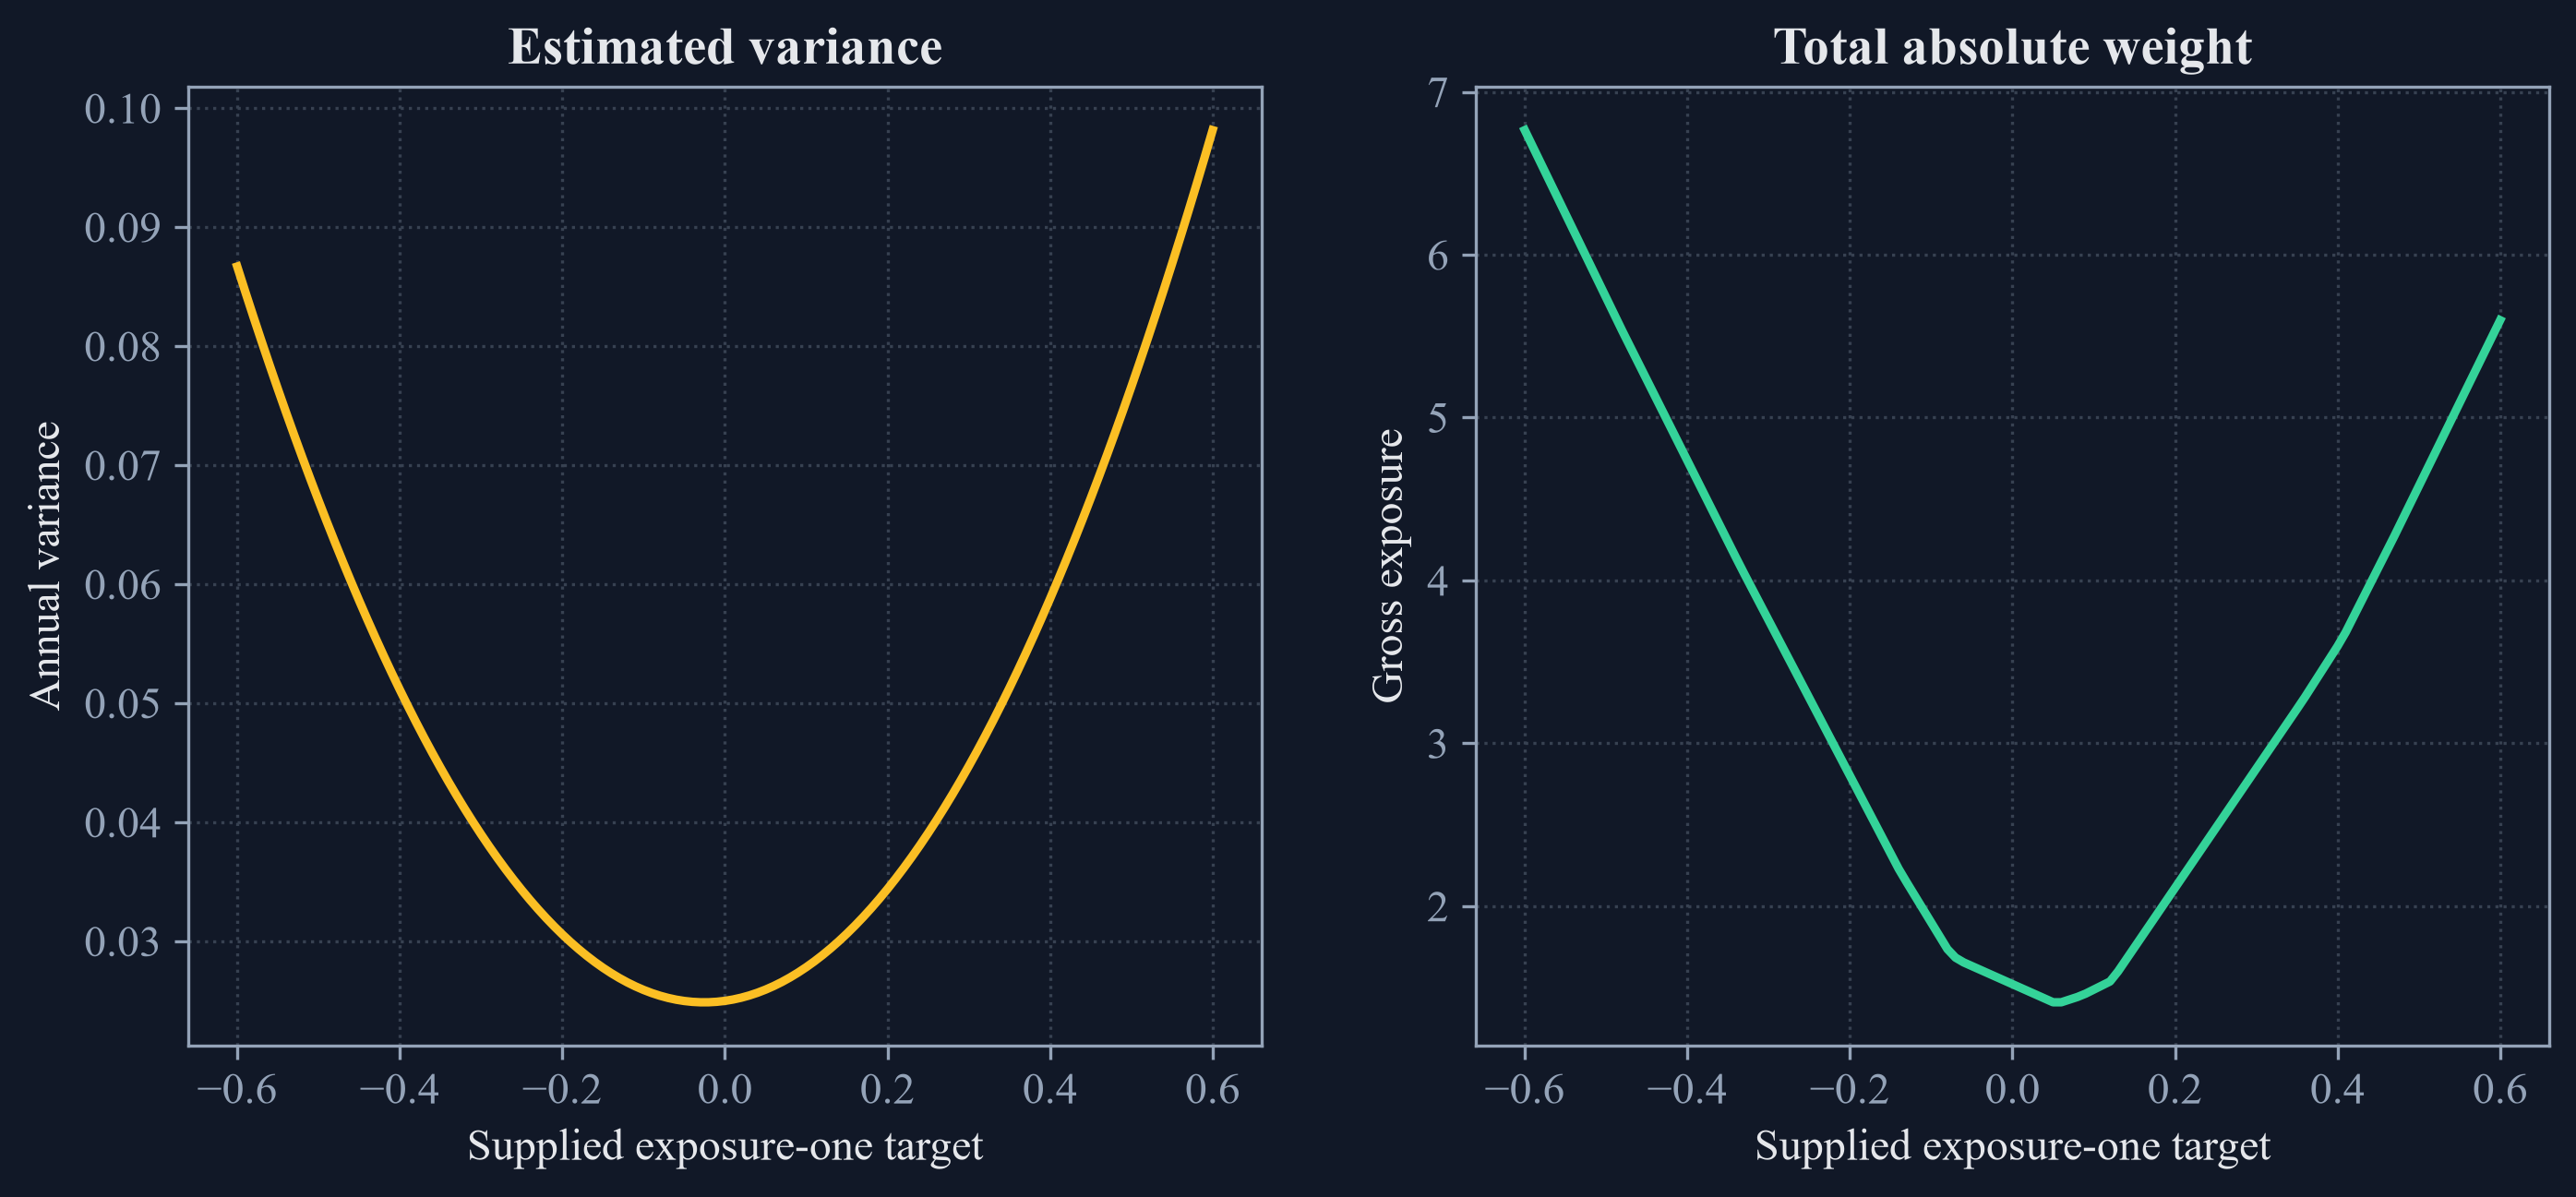

In [5]:
public_assets = list(industry_returns.columns[:12])
public_sample = industry_returns[public_assets]
public_covariance = public_sample.cov().to_numpy() * 252.0
asset_count = len(public_assets)
supplied_first = np.linspace(-1.0, 1.0, asset_count)
supplied_second = np.cos(np.linspace(0.0, np.pi, asset_count))
supplied_first = supplied_first - supplied_first.mean()
supplied_second = supplied_second - supplied_second.mean()
public_exposures = np.column_stack([np.ones(asset_count), supplied_first, supplied_second])
public_targets = np.array([1.0, 0.0, 0.0])
public_weights = minimum_variance_factor_weights(public_covariance, public_exposures, public_targets)
budget_only_weights = minimum_variance_factor_weights(public_covariance, np.ones((asset_count, 1)), np.array([1.0]))
public_achieved = public_exposures.T @ public_weights
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Return type', 'Analysis start', 'Analysis end', 'Complete dates', 'Industry portfolios'], 'Value': ['49 Industry Portfolios daily archive', 'Kenneth R. French Data Library', 'Daily value-weighted return', str(public_sample.index.min().date()), str(public_sample.index.max().date()), len(public_sample), public_sample.shape[1]]})
save_table(data_provenance, 'allocation_data_provenance', 'Public data used for the constrained allocation example.', 'tab:chapter27-allocation-data')
display(data_provenance)
public_weight_table = pd.DataFrame({'Industry': public_assets, 'Budget-only weight': budget_only_weights, 'Three-constraint weight': public_weights, 'Supplied exposure one': supplied_first, 'Supplied exposure two': supplied_second})
save_table(public_weight_table, 'allocation_public_weights', 'Weights under a budget constraint and two additional supplied exposure targets.', 'tab:chapter27-allocation-public-weights')
display(public_weight_table)
public_exposure_table = pd.DataFrame({'Constraint': ['Budget', 'Supplied exposure one', 'Supplied exposure two'], 'Target': public_targets, 'Achieved exposure': public_achieved, 'Absolute difference': np.abs(public_achieved - public_targets)})
save_table(public_exposure_table, 'allocation_public_exposures', 'Achieved exposures in the public covariance example.', 'tab:chapter27-allocation-public-exposures')
display(public_exposure_table)
public_summary = pd.DataFrame([{'Portfolio': 'Budget only', 'Annual variance': portfolio_variance(public_covariance, budget_only_weights), 'Annual volatility': math.sqrt(portfolio_variance(public_covariance, budget_only_weights)), 'Gross exposure': np.abs(budget_only_weights).sum(), 'Largest absolute weight': np.abs(budget_only_weights).max()}, {'Portfolio': 'Three supplied targets', 'Annual variance': portfolio_variance(public_covariance, public_weights), 'Annual volatility': math.sqrt(portfolio_variance(public_covariance, public_weights)), 'Gross exposure': np.abs(public_weights).sum(), 'Largest absolute weight': np.abs(public_weights).max()}])
save_table(public_summary, 'allocation_public_summary', 'Variance and weight summaries under the public covariance estimate.', 'tab:chapter27-allocation-public-summary')
display(public_summary)
figure, axis = plt.subplots(figsize=(10.8, 5.0))
locations = np.arange(asset_count)
width = 0.38
axis.bar(locations - width / 2.0, budget_only_weights, width=width, color=palette['muted'], label='Budget only')
axis.bar(locations + width / 2.0, public_weights, width=width, color=palette['cyan'], label='Three supplied targets')
axis.axhline(0.0, color=palette['text'], linewidth=0.8)
axis.set_xticks(locations)
axis.set_xticklabels(public_assets, rotation=50, ha='right')
axis.set_ylabel('Portfolio weight')
axis.set_title('Public covariance with explicit supplied exposure targets')
axis.legend()
axis.grid(True, axis='y')
save_figure(figure, 'allocation_public_weights')
public_target_values = np.linspace(-0.6, 0.6, 121)
public_target_weights = np.array([minimum_variance_factor_weights(public_covariance, public_exposures, [1.0, value, 0.0]) for value in public_target_values])
public_target_variances = np.array([portfolio_variance(public_covariance, weights) for weights in public_target_weights])
public_target_rows = []
for value in [-0.6, -0.3, 0.0, 0.3, 0.6]:
    weights = minimum_variance_factor_weights(public_covariance, public_exposures, [1.0, value, 0.0])
    public_target_rows.append({'Supplied exposure-one target': value, 'Annual variance': portfolio_variance(public_covariance, weights), 'Annual volatility': math.sqrt(portfolio_variance(public_covariance, weights)), 'Gross exposure': np.abs(weights).sum()})
public_target_table = pd.DataFrame(public_target_rows)
save_table(public_target_table, 'allocation_public_target_sweep', 'Risk and gross exposure as a supplied target changes.', 'tab:chapter27-allocation-public-target-sweep')
display(public_target_table)
figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.5))
axes[0].plot(public_target_values, public_target_variances, color=palette['amber'], linewidth=2.2)
axes[0].set_xlabel('Supplied exposure-one target')
axes[0].set_ylabel('Annual variance')
axes[0].set_title('Estimated variance')
axes[0].grid(True)
axes[1].plot(public_target_values, np.abs(public_target_weights).sum(axis=1), color=palette['green'], linewidth=2.2)
axes[1].set_xlabel('Supplied exposure-one target')
axes[1].set_ylabel('Gross exposure')
axes[1].set_title('Total absolute weight')
axes[1].grid(True)
save_figure(figure, 'allocation_public_target_variance')


## Checking the portfolio solution near numerical boundaries

A computed allocation is accepted only when every scaled exposure residual is small relative to its target:

$$
\left|\widetilde B^{\mathsf T}w-\widetilde c\right|_j
\leq
\begin{cases}
10^{-10}|\widetilde c_j|,&\widetilde c_j\ne0,\\
10^{-12},&\widetilde c_j=0.
\end{cases}
$$

Here, $\widetilde B$ and $\widetilde c$ are the exposure matrix and target vector after positive column scaling, $j$ labels a constraint, and the two tolerances protect nonzero and zero targets without changing their units.

,Column separation,Exposure condition number,Gross exposure,Largest exposure residual,Accepted
0,1,3.403013,2.114267,0,True
1,0.01,327.543229,2.114267,0,True
2,0.0001,32773.479656,2.114267,0,True
3,0.000001,3277367,2.114267,0,True
4,0,327736763,NaN,NaN,False
5,0,32773667992,NaN,NaN,False
6,0,3277003776665,NaN,NaN,False


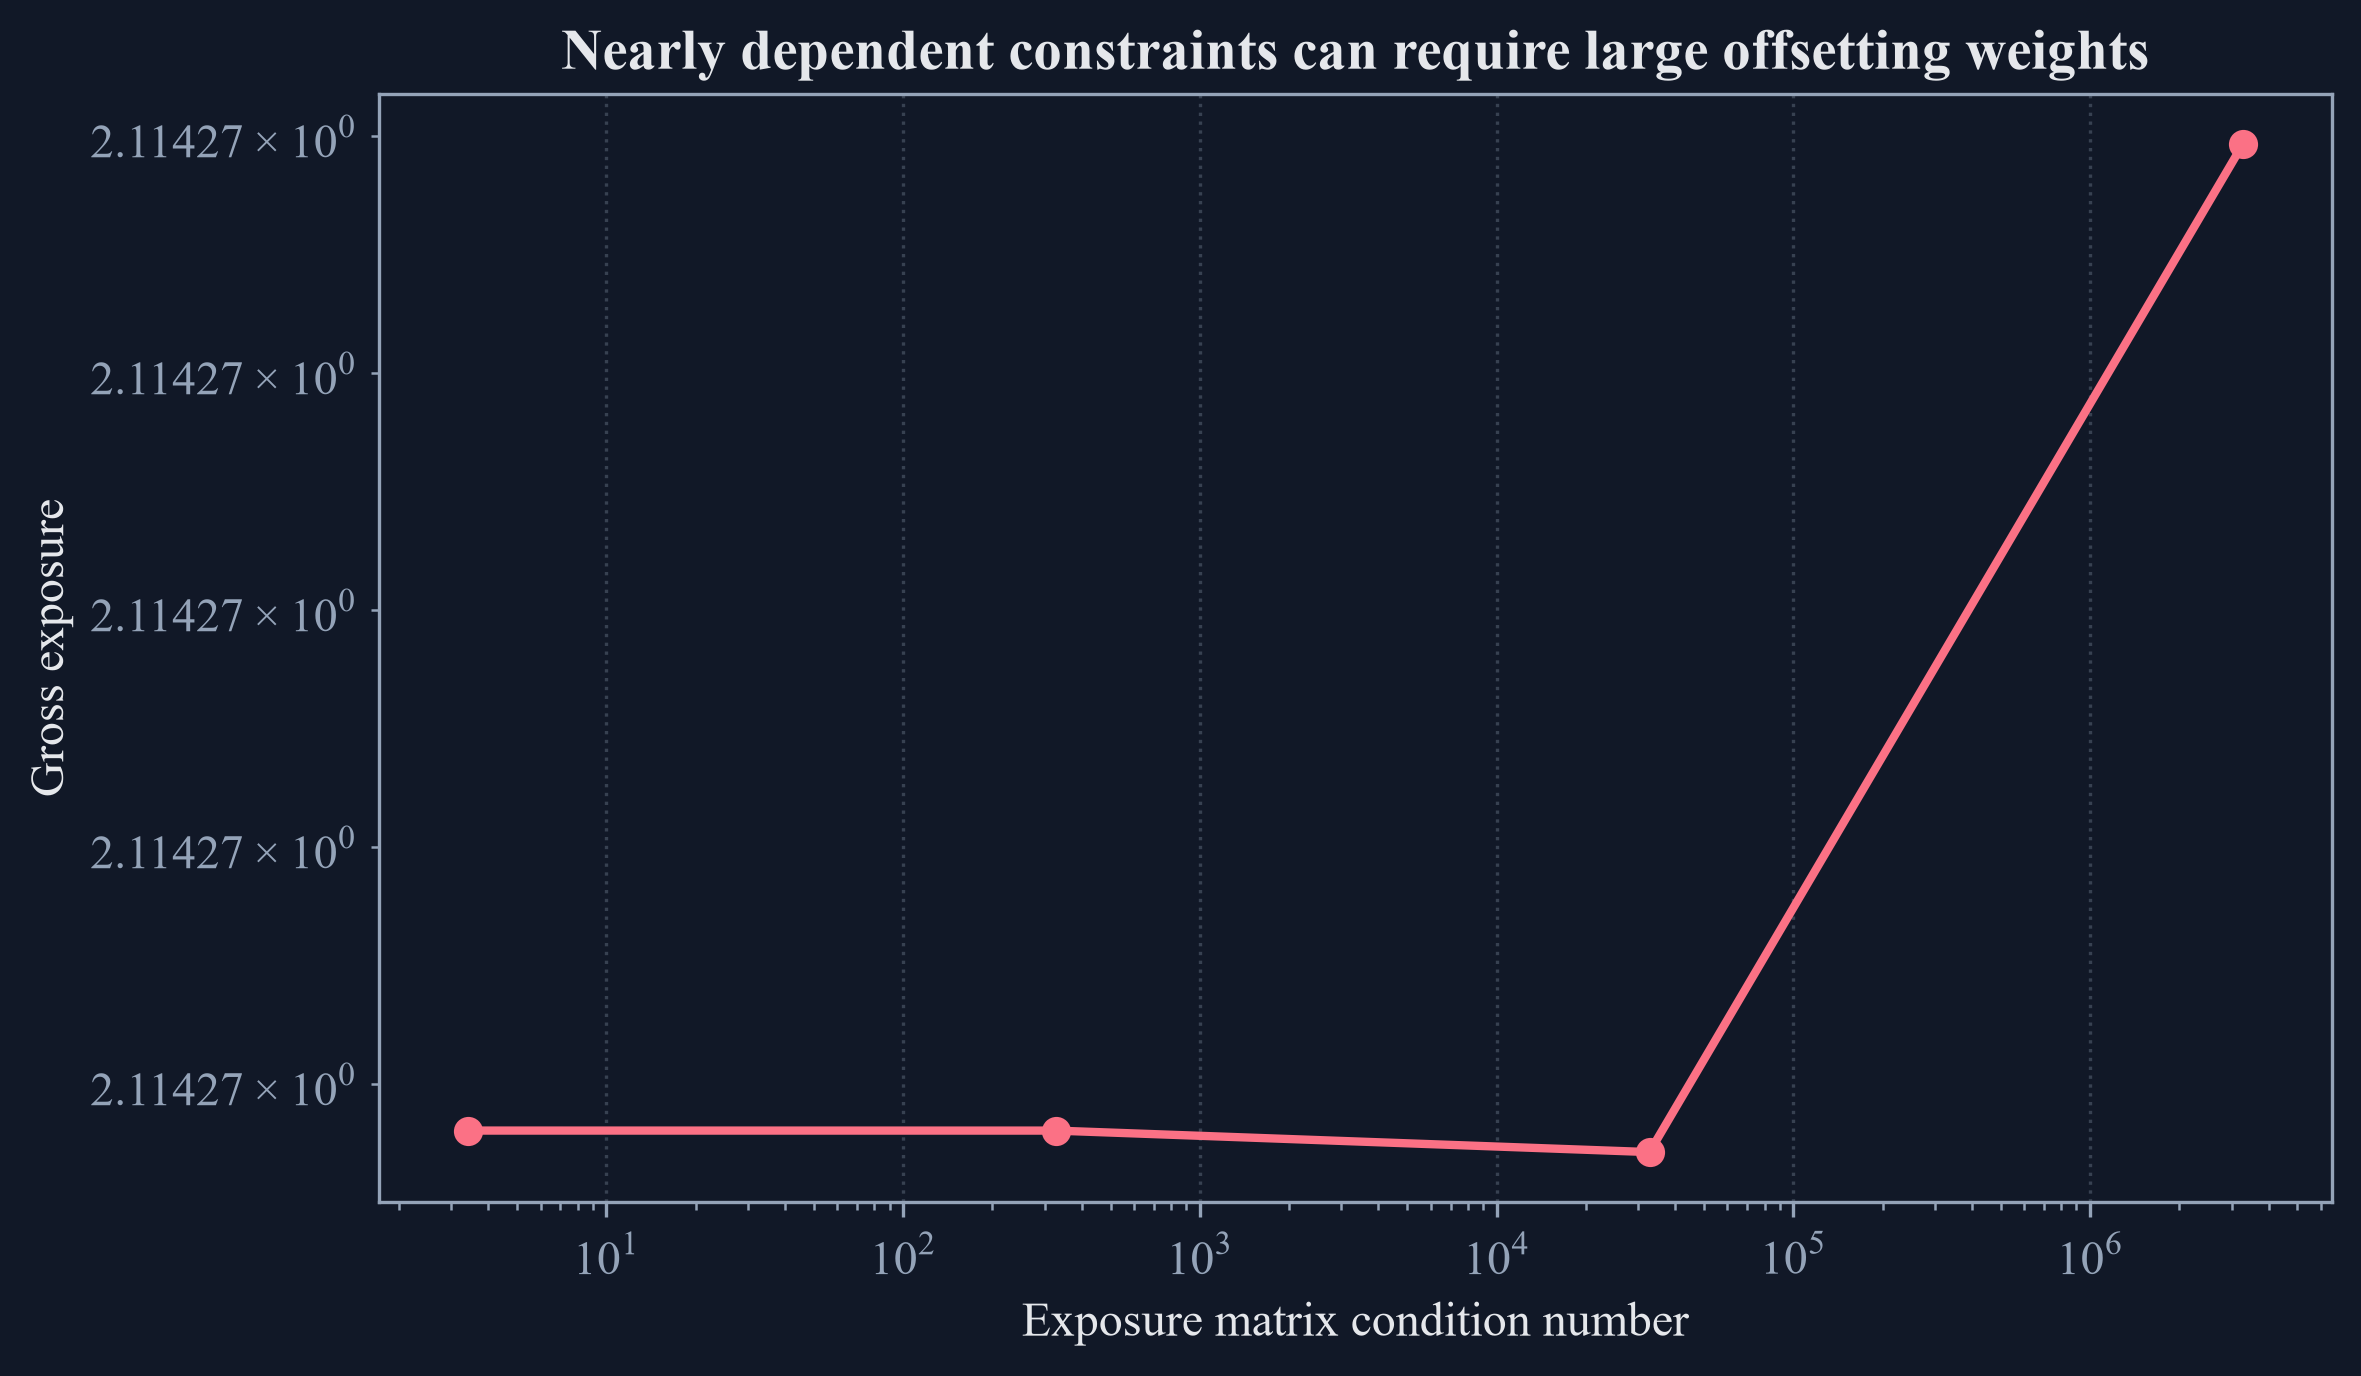

,Check,Expected result,Observed result,Passed
0,Nonsymmetric covariance,ValueError,ValueError,True
1,Singular covariance,ValueError,ValueError,True
2,Redundant exposure columns,ValueError,ValueError,True
3,Wrong target length,ValueError,ValueError,True
4,Nonfinite target,ValueError,ValueError,True
5,Complex exposure,ValueError,ValueError,True


,Public group,Count,Notebook coverage
0,Minimum-variance allocation function,1,"Formula, first-order conditions, perturbations..."
1,Released optimizer checks,33,Numerical identities and representative bounda...


,Question,Answer
0,What determines the solution?,"Covariance, supplied exposure matrix, and targ..."
1,What must hold?,Positive-definite covariance and independent e...
2,What does public return history provide?,An observed covariance estimate
3,What does the calculation not establish?,Whether the supplied exposures are causally co...


In [6]:
condition_rows = []
condition_levels = [1.0, 1e-2, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12]
condition_covariance = np.diag([1.0, 1.3, 1.8, 2.4])
base_one = np.array([1.0, -1.0, 0.5, -0.5])
base_two = np.array([0.5, 0.2, -0.8, 0.1])
for separation in condition_levels:
    exposures = np.column_stack([np.ones(4), base_one, base_one + separation * base_two])
    try:
        weights = minimum_variance_factor_weights(condition_covariance, exposures, [1.0, 0.0, separation])
        residual = np.max(np.abs(exposures.T @ weights - np.array([1.0, 0.0, separation])))
        condition_rows.append({"Column separation": separation, "Exposure condition number": np.linalg.cond(exposures), "Gross exposure": np.abs(weights).sum(), "Largest exposure residual": residual, "Accepted": True})
    except ValueError:
        condition_rows.append({"Column separation": separation, "Exposure condition number": np.linalg.cond(exposures), "Gross exposure": np.nan, "Largest exposure residual": np.nan, "Accepted": False})
condition_table = pd.DataFrame(condition_rows)
save_table(condition_table, "allocation_condition_sensitivity", "Allocation behavior as two supplied exposure columns approach dependence.", "tab:chapter27-allocation-condition")
display(condition_table)

figure, axis = plt.subplots(figsize=(8.4, 4.8))
accepted_condition = condition_table[condition_table["Accepted"]]
axis.plot(accepted_condition["Exposure condition number"], accepted_condition["Gross exposure"], marker="o", color=palette["rose"], linewidth=2.0)
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel("Exposure matrix condition number")
axis.set_ylabel("Gross exposure")
axis.set_title("Nearly dependent constraints can require large offsetting weights")
axis.grid(True)
save_figure(figure, "allocation_condition_sensitivity")

input_checks = pd.DataFrame([
    contract_result("Nonsymmetric covariance", lambda: minimum_variance_factor_weights([[1.0, 0.4], [0.1, 1.0]], np.eye(2), [1.0, 0.0]), "ValueError"),
    contract_result("Singular covariance", lambda: minimum_variance_factor_weights([[1.0, 1.0], [1.0, 1.0]], np.eye(2), [1.0, 0.0]), "ValueError"),
    contract_result("Redundant exposure columns", lambda: minimum_variance_factor_weights(np.eye(3), np.array([[1.0, 1.0], [0.0, 0.0], [1.0, 1.0]]), [0.0, 1.0]), "ValueError"),
    contract_result("Wrong target length", lambda: minimum_variance_factor_weights(np.eye(2), np.eye(2), [1.0]), "ValueError"),
    contract_result("Nonfinite target", lambda: minimum_variance_factor_weights(np.eye(2), np.eye(2), [1.0, np.nan]), "ValueError"),
    contract_result("Complex exposure", lambda: minimum_variance_factor_weights(np.eye(2), np.array([[1.0 + 1.0j, 0.0], [0.0, 1.0]]), [1.0, 0.0]), "ValueError"),
])
save_table(input_checks, "allocation_input_checks", "Rejected inputs at the public allocation boundary.", "tab:chapter27-allocation-input")
display(input_checks)

public_surface = pd.DataFrame([
    {"Public group": "Minimum-variance allocation function", "Count": 1, "Notebook coverage": "Formula, first-order conditions, perturbations, targets, units, public covariance, and boundaries"},
    {"Public group": "Released optimizer checks", "Count": 33, "Notebook coverage": "Numerical identities and representative boundary families"},
])
save_table(public_surface, "allocation_public_surface", "Released public allocation material covered by Section 27.1.", "tab:chapter27-allocation-public-surface")
display(public_surface)

section_summary = pd.DataFrame([
    {"Question": "What determines the solution?", "Answer": "Covariance, supplied exposure matrix, and target vector"},
    {"Question": "What must hold?", "Answer": "Positive-definite covariance and independent exposure columns"},
    {"Question": "What does public return history provide?", "Answer": "An observed covariance estimate"},
    {"Question": "What does the calculation not establish?", "Answer": "Whether the supplied exposures are causally correct"},
])
save_table(section_summary, "allocation_section_summary", "Interpretation limits for target-exposure allocation.", "tab:chapter27-allocation-section-summary")
display(section_summary)

## Tests

In [7]:
np.testing.assert_allclose(quick_weights, [-2.0 / 7.0, 5.0 / 7.0, 2.0 / 7.0], atol=2e-15)
np.testing.assert_allclose(quick_achieved, quick_targets, atol=2e-15)
np.testing.assert_allclose(quick_weights, oracle_weights, atol=2e-15)
assert np.max(np.abs(quick_stationarity)) < 2e-15
assert np.argmin(feasible_variances) == len(perturbations) // 2
assert invariance_table['Passed'].all()
np.testing.assert_allclose(public_achieved, public_targets, atol=2e-12)
assert input_checks['Passed'].all()
assert public_surface['Count'].sum() == 34
for stem in ['allocation_feasible_variance', 'allocation_target_paths', 'allocation_public_weights', 'allocation_public_target_variance', 'allocation_condition_sensitivity']:
    assert (FIGURES / f'{stem}.pdf').is_file()
for stem in ['allocation_quickstart_weights', 'allocation_kkt_checks', 'allocation_feasible_perturbations', 'allocation_target_sweep', 'allocation_invariance_checks', 'allocation_square_system', 'allocation_data_provenance', 'allocation_public_weights', 'allocation_public_exposures', 'allocation_public_summary', 'allocation_public_target_sweep', 'allocation_condition_sensitivity', 'allocation_input_checks', 'allocation_public_surface', 'allocation_section_summary']:
    assert (TABLES / f'{stem}.tex').is_file()
